In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy import interpolate
from scipy.stats import gaussian_kde
import glob
import pickle
import matplotlib
import os
from numpy import correlate

matplotlib.rcParams['font.size'] = 8.0
matplotlib.rcParams['pdf.fonttype'] = 42
mpl.rcParams['font.family'] = 'Arial'

In [2]:
Fs = 3e4
L = 600
out_path = './6_NaturalBehavior/Clipped_test/'

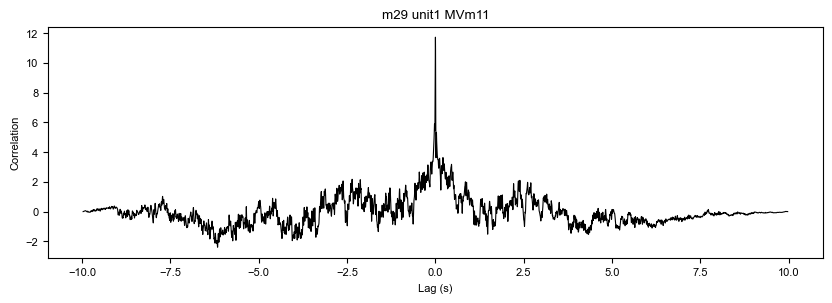

m29 unit1 MVm11: peak=11.721 at lag=0.0004s | at_zero=11.710


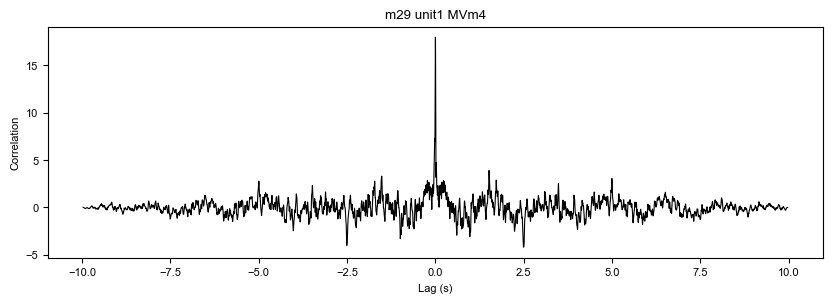

m29 unit1 MVm4: peak=17.985 at lag=0.0005s | at_zero=17.954


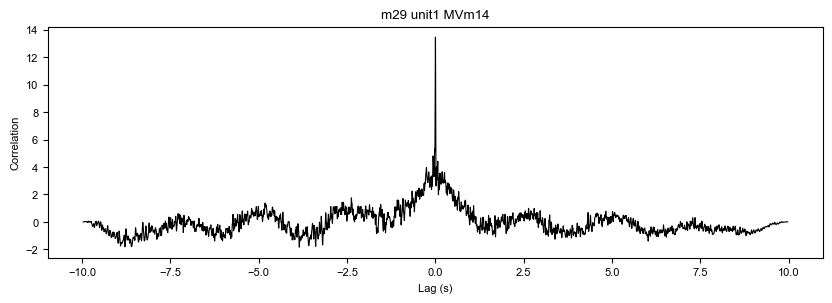

m29 unit1 MVm14: peak=13.465 at lag=0.0004s | at_zero=13.443


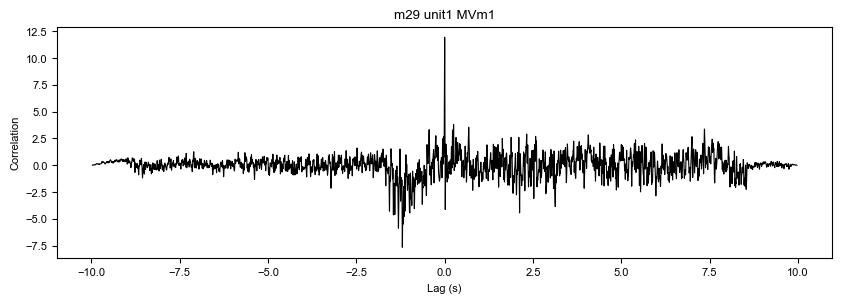

m29 unit1 MVm1: peak=11.934 at lag=0.0002s | at_zero=11.930


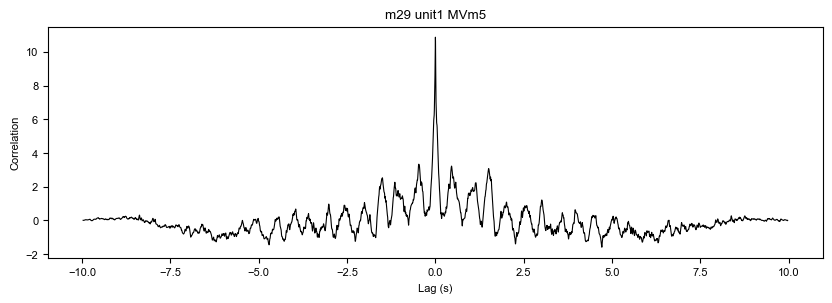

m29 unit1 MVm5: peak=10.870 at lag=0.0001s | at_zero=10.870


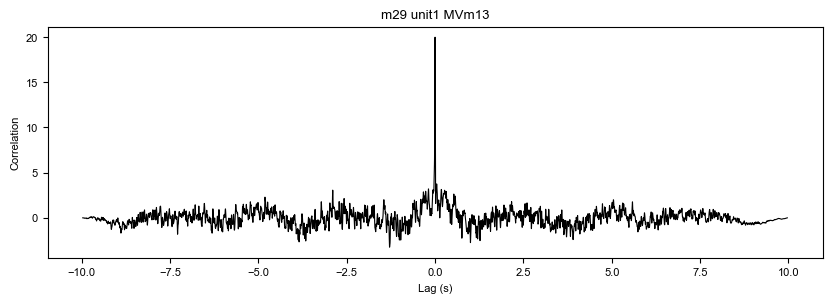

m29 unit1 MVm13: peak=19.979 at lag=0.0004s | at_zero=19.955


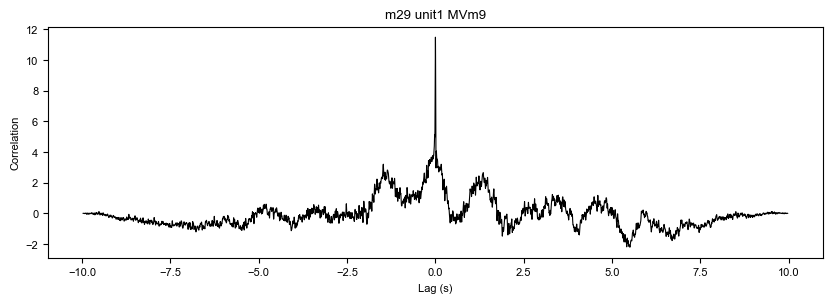

m29 unit1 MVm9: peak=11.477 at lag=0.0004s | at_zero=11.463


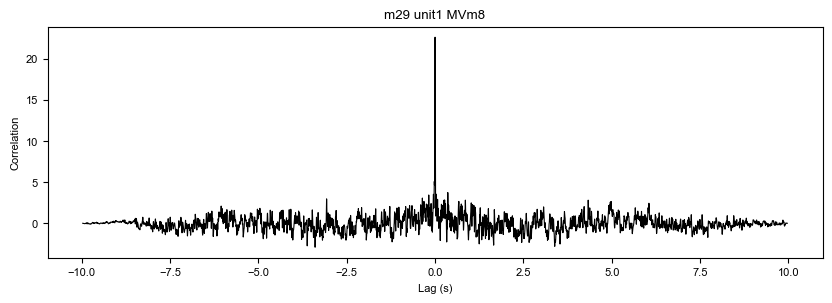

m29 unit1 MVm8: peak=22.586 at lag=0.0005s | at_zero=22.516


In [8]:
for filepath in glob.glob('./6_NaturalBehavior/Clipped_test/*_Prediction.pickle'):
    with open(filepath, 'rb') as f:
        savedData = pickle.load(f)

    moth     = os.path.basename(filepath).split('_')[0]
    unitID   = os.path.basename(filepath).split('_')[1]
    vid_moth = os.path.basename(filepath).split('_')[3]

    if moth != 'm31' or unit != unit2:
            continue
    
    p_spike   = savedData[4]
    upsampled = savedData[6]
    
    predcorr = np.correlate(p_spike - np.mean(p_spike),
                        upsampled[L:] - np.mean(upsampled[L:]), mode='full')
    predcorr_normalised = predcorr / np.std(predcorr)
    lags = np.arange(-(len(p_spike)-1), len(p_spike)) / Fs 
    predcorr = np.correlate(p_spike[valid] - np.mean(p_spike[valid]),
                        upsampled[valid] - np.mean(upsampled[valid]), mode='full') #centers it around zero- not baseline at everypoint
    #predcorr_normalised = predcorr / (len(p_spike[valid]) * np.std(p_spike[valid]) * np.std(upsampled[valid]))# n*std*stdy
    predcorr_normalised = predcorr / np.std(predcorr)
    lags     = np.arange(-(valid.sum()-1), valid.sum()) / Fs # wha time offset best matches the prediction movement
    peak_idx = np.argmax(np.abs(predcorr_normalised))
    zero_idx = np.argmin(np.abs(lags))

    plt.figure(figsize=(10, 3))
    plt.plot(lags, predcorr_normalised, 'k', linewidth=0.8)
    plt.xlabel('Lag (s)')
    plt.ylabel('Correlation')
    plt.title(f'{moth} {unitID} {vid_moth}')
    plt.show()

    print(f'{moth} {unitID} {vid_moth}: peak={predcorr_normalised[peak_idx]:.3f} at lag={lags[peak_idx]:.4f}s | at_zero={predcorr_normalised[zero_idx]:.3f}')

    
    #predcorr_df = pd.DataFrame({'lag_seconds': lags, 'predcorr_normalised': predcorr_normalised})
    #predcorr_df.to_csv(out_path + moth + '_' + unitID + '_for_' + vid_moth + '_predcorrnorm.csv', index=False)